# 1. Problem Statement

**Problem** :
- Memprediksi platform untuk memainkan game nya. seperti apakah compatible menggunakan mac atau tidak mengingat

**Justifikasi** :
- https://www.howtogeek.com/macos-is-finally-becoming-a-legit-gaming-platform/

**User/pengguna** : gamers yang hendak mengecek klasifikasi pada suatu video games seperti platform yang compatible terutama pada mac agar mereka bisa mempertimbangkan untuk memainkan game nya atau tidak

# 2. Import Libraries

In [ ]:
import pandas as pd
import numpy as np
from scipy.stats import kendalltau
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.metrics import roc_curve, roc_auc_score
from feature_engine.outliers import Winsorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
from scipy.stats import randint, uniform
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, StratifiedKFold
from sklearn.model_selection import cross_validate
from sklearn.metrics import ConfusionMatrixDisplay

# 3. Data Loading

In [16]:
df = pd.read_csv('games_march2025_full.csv')
df.head(3)

,appid,name,release_date,required_age,price,dlc_count,detailed_description,about_the_game,short_description,reviews,...,average_playtime_2weeks,median_playtime_forever,median_playtime_2weeks,discount,peak_ccu,tags,pct_pos_total,num_reviews_total,pct_pos_recent,num_reviews_recent
0,730,Counter-Strike 2,2012-08-21,0,0.0,1,"For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...","For over two decades, Counter-Strike has offer...",NaN,...,879,5174,350,0,1212356,"{'FPS': 90857, 'Shooter': 65397, 'Multiplayer'...",86,8632939,82,96473
1,578080,PUBG: BATTLEGROUNDS,2017-12-21,0,0.0,0,"LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...","LAND, LOOT, SURVIVE! Play PUBG: BATTLEGROUNDS ...",Play PUBG: BATTLEGROUNDS for free. Land on str...,NaN,...,0,0,0,0,616738,"{'Survival': 14838, 'Shooter': 12727, 'Battle ...",59,2513842,68,16720
2,570,Dota 2,2013-07-09,0,0.0,2,"The most-played game on Steam. Every day, mill...","The most-played game on Steam. Every day, mill...","Every day, millions of players worldwide enter...",“A modern multiplayer masterpiece.” 9.5/10 – D...,...,1536,898,892,0,555977,"{'Free to Play': 59933, 'MOBA': 20158, 'Multip...",81,2452595,80,29366


Beberapa hal yang dilakukan dalam data loading :

- Kolom 'appid', 'detailed_description', 'about_the_game', 'short_description', 'header_image', 'website', 'support_url', 'support_email', 'packages', 'screenshots, 'movies', 'name' dihapus karena nilai masing-masing data semuanya unik jadi machine learning akan berat untuk menjalankan program nya
- Kolom 'reviews', 'metacritic_url', 'score_rank' , 'notes' dihapus karena terlalu banyak missing value khawatir analisis menjadi bias
- Kolom 'tags' dihapus karena nilai sudah diwakilkan dengan kolom 'genre'
- Kolom 'developer' dihapus karena cukup mengetahui dari nilai pada kolom 'publisher'
- Kolom 'average_playtime_forever', 'average_playtime_2weeks', 'median_playtime_forever', 'median_playtime_2weeks', 'pct_pos_total', 'num_reviews_total', 'pct_pos_recent', 'num_reviews_recent' dihapus karena banyak nilai 0 dan -1 yang membuat data menjadi sulit dilakukan analisa
- Hilangkan nilai 0 pada kolom 'price'
- Ubah nilai kolom 'release_date' menjadi quartal agar mengurangi banyak unik values

In [17]:
df = df.drop(columns=['appid', 'name', 'developers', 'detailed_description', 'about_the_game', 'short_description', 'header_image', 'website', 
                        'support_url', 'support_email', 'reviews', 'metacritic_url', 'score_rank', 'packages', 'screenshots', 
                        'movies', 'tags', 'notes', 'user_score', 'average_playtime_forever', 'average_playtime_2weeks', 
                        'median_playtime_forever', 'median_playtime_2weeks', 'pct_pos_total', 'num_reviews_total', 'pct_pos_recent', 
                        'num_reviews_recent'])

df = df[df['price'] != 0.00].reset_index(drop=True)

df['release_date'] = pd.to_datetime(df['release_date'], errors='coerce')
df['release_date'] = df['release_date'].dt.quarter

Save datanya menjadi file csv yang baru

In [18]:
df.to_csv('games.csv', index = False)

**Note** : 

- Dikarenakan size file csv nya 400 mb sehingga tidak bisa dilakukan push ke github karena keterbatasan memori

- File csv bisa di-unduh pada link google drive berikut https://drive.google.com/drive/folders/19zRFjrooeTkH8zTyfcYQKbrpbiKREI5a?usp=sharing

- Untuk File dataset juga bisa diunduh melalui website Kaggle berikut : https://www.kaggle.com/datasets/artermiloff/steam-games-dataset/data
- Selanjutnya melakukan load file csv games.csv yang sudah dilakukan handling sebelumnya

Load kembali csv menggunakan variable baru

In [19]:
df1 = pd.read_csv('games.csv')
df1.head(3)

,release_date,required_age,price,dlc_count,windows,mac,linux,metacritic_score,achievements,recommendations,supported_languages,full_audio_languages,publishers,categories,genres,positive,negative,estimated_owners,discount,peak_ccu
0,4,17,19.99,9,True,False,False,0,0,1160724,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",['Ubisoft'],"['Single-player', 'Multi-player', 'PvP', 'Onli...",['Action'],312816,64201,0 - 20000,0,0
1,4,17,19.99,9,True,False,False,0,0,1160500,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",['Ubisoft'],"['Single-player', 'Multi-player', 'PvP', 'Onli...",['Action'],312397,64151,0 - 20000,0,0
2,4,17,19.99,9,True,False,False,0,0,1160766,"['English', 'French', 'Italian', 'German', 'Sp...","['English', 'French', 'Italian', 'German', 'Sp...",['Ubisoft'],"['Single-player', 'Multi-player', 'PvP', 'Onli...",['Action'],312232,64137,0 - 20000,0,0


In [20]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 75528 entries, 0 to 75527
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   release_date          75528 non-null  int64  
 1   required_age          75528 non-null  int64  
 2   price                 75528 non-null  float64
 3   dlc_count             75528 non-null  int64  
 4   windows               75528 non-null  bool   
 5   mac                   75528 non-null  bool   
 6   linux                 75528 non-null  bool   
 7   metacritic_score      75528 non-null  int64  
 8   achievements          75528 non-null  int64  
 9   recommendations       75528 non-null  int64  
 10  supported_languages   75528 non-null  str    
 11  full_audio_languages  75528 non-null  str    
 12  publishers            75528 non-null  str    
 13  categories            75528 non-null  str    
 14  genres                75528 non-null  str    
 15  positive              75528 no

# 4. EDA

## 4.1. Correlation Check

Melakukan pengecekan apakah fitur-fitur nya mempunyai pengaruh pada target untuk melakukan modeling

In [21]:
p_values = []
interpretasi = []
cols = []

for col in ['required_age','metacritic_score','achievements','recommendations','positive','negative',
                   'discount','peak_ccu', 'dlc_count', 'genres', 'categories',
                   'supported_languages', 'full_audio_languages', 'price', 'windows', 'linux', 'release_date']:
    corr_coef, p_value = kendalltau(df1[col], df1['mac'])

    p_values.append(p_value)
    cols.append(col)

    if p_value < 0.05:
        interpretasi.append('ada korelasi')
    else:
        interpretasi.append('ga ada korelasi')

pd.DataFrame({'nama kolom': cols,
              'hasil': interpretasi})

,nama kolom,hasil
0,required_age,ada korelasi
1,metacritic_score,ada korelasi
2,achievements,ada korelasi
3,recommendations,ada korelasi
4,positive,ada korelasi
5,negative,ada korelasi
6,discount,ada korelasi
7,peak_ccu,ada korelasi
8,dlc_count,ada korelasi
9,genres,ada korelasi


Hasil menunjukan bahwa hampir semua fitur mempengaruhi nilai pada suatu target, ini menandakan bahwa modeling dapat dilakukan dengan kolom 'mac' sebagai target

## 4.2. Distribution Check ('mac')

mac
False    60685
True     14843
Name: count, dtype: int64
mac
False    0.803477
True     0.196523
Name: proportion, dtype: float64


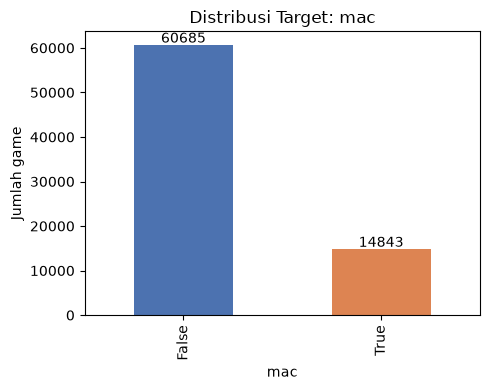

In [22]:
target_counts = df1['mac'].value_counts()
target_props = df1['mac'].value_counts(normalize=True)

print(target_counts)
print(target_props)

fig, ax = plt.subplots(figsize=(5, 4))
target_counts.plot(kind='bar', color=['#4C72B0', '#DD8452'], ax=ax)
ax.set_title('Distribusi Target: mac')
ax.set_xlabel('mac')
ax.set_ylabel('Jumlah game')

for i, v in enumerate(target_counts):
    ax.text(i, v + 500, str(v), ha='center')

plt.tight_layout()
plt.show()

Dari hasil berikut bahwa banyak game yang tidak compatible pada platform mac

               positive     negative
price_bin                           
0-5          263.956202    42.955366
5-10         664.556949    74.274540
10-20       2235.561485   268.798556
20-50       7245.830421  1098.351447
50+        16482.179487  3135.273504


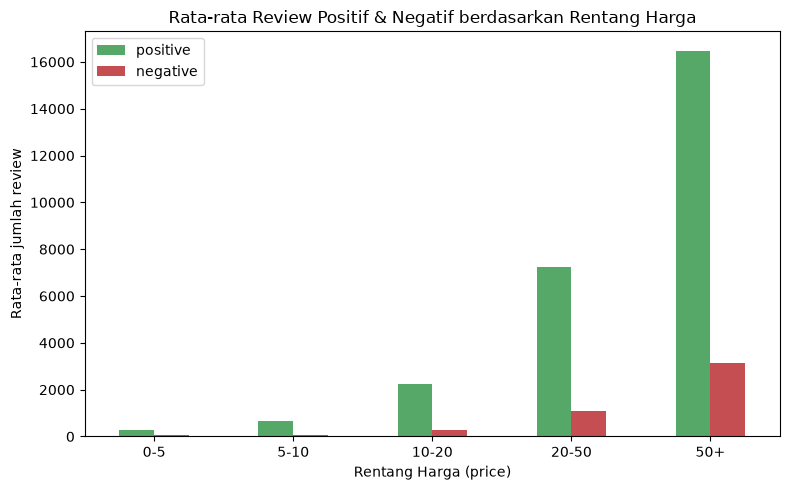

In [23]:
bins = [0, 5, 10, 20, 50, df1['price'].max()]
labels = ['0-5', '5-10', '10-20', '20-50', '50+']
df1['price_bin'] = pd.cut(df1['price'], bins=bins, labels=labels, include_lowest=True)

review_by_price = df1.groupby('price_bin', observed=True)[['positive', 'negative']].mean()

print(review_by_price)

fig, ax = plt.subplots(figsize=(8, 5))
review_by_price.plot(kind='bar', ax=ax, color=['#55A868', '#C44E52'])
ax.set_title('Rata-rata Review Positif & Negatif berdasarkan Rentang Harga')
ax.set_xlabel('Rentang Harga (price)')
ax.set_ylabel('Rata-rata jumlah review')
ax.legend(['positive', 'negative'])
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Dari gambar tersebut menampilkan terdapat kenaikan signifikan pada nilai positif ketika harga semakin tinggi. Ini masuk akal karena game mahal biasanya AAA/sudah lama beredar dan punya basis pemain lebih besar. 

Jadi jika semakin banyak review ada kemungkinan game tersebut memang sudah lama beredar, dan kenapa di harga tinggi banyak review nya karena buyer/gamer tidak terlalu memerhatikan game yang tergolong murah jadi ketika game tersebut tinggi maka banyak pembeli mempunyai ekspektasi tinggi sehingga menjadikan banyak yang mencoba memainkan game tersebut.

# 5. Feature Engineering

## 5.1. Cardinality

In [24]:
df1_cardy = df1.copy()

# menjadikan 25 data teratas dan sisanya dijadikan other
top_k = df1_cardy['publishers'].value_counts().nlargest(25).index
df1_cardy['publishers'] = df1_cardy['publishers'].where(df1_cardy['publishers'].isin(top_k), 'Other')

top_k = df1_cardy['genres'].value_counts().nlargest(25).index
df1_cardy['genres'] = df1_cardy['genres'].where(df1_cardy['genres'].isin(top_k), 'Other')

top_k = df1_cardy['categories'].value_counts().nlargest(25).index
df1_cardy['categories'] = df1_cardy['categories'].where(df1_cardy['categories'].isin(top_k), 'Other')

top_k = df1_cardy['supported_languages'].value_counts().nlargest(25).index
df1_cardy['supported_languages'] = df1_cardy['supported_languages'].where(df1_cardy['supported_languages'].isin(top_k), 'Other')

top_k = df1_cardy['full_audio_languages'].value_counts().nlargest(25).index
df1_cardy['full_audio_languages'] = df1_cardy['full_audio_languages'].where(df1_cardy['full_audio_languages'].isin(top_k), 'Other')

df1_cardy.head(3)

,release_date,required_age,price,dlc_count,windows,mac,linux,metacritic_score,achievements,recommendations,...,full_audio_languages,publishers,categories,genres,positive,negative,estimated_owners,discount,peak_ccu,price_bin
0,4,17,19.99,9,True,False,False,0,0,1160724,...,Other,Other,Other,['Action'],312816,64201,0 - 20000,0,0,10-20
1,4,17,19.99,9,True,False,False,0,0,1160500,...,Other,Other,Other,['Action'],312397,64151,0 - 20000,0,0,10-20
2,4,17,19.99,9,True,False,False,0,0,1160766,...,Other,Other,Other,['Action'],312232,64137,0 - 20000,0,0,10-20


In [25]:
df1_cardy['release_date'].value_counts()

release_date
4    20615
1    19541
3    18003
2    17369
Name: count, dtype: int64

## 5.2. Splitting Train & Test

In [26]:
X = df1_cardy.drop(['mac'], axis = 1)
y = df1_cardy['mac']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 7)
print('Train Size', X_train.shape)
print('Test Size', X_test.shape)

print('Train Size', y_train.shape)
print('Test Size', y_test.shape)

Train Size (60422, 20)
Test Size (15106, 20)
Train Size (60422,)
Test Size (15106,)


## 5.3. Handling Outlier

Melakukan pengecekan outlier

In [27]:
num_cols = list(X_train.select_dtypes(include='number').columns)
listItem = []

for col in num_cols:
    skew_val = round(X_train[col].skew(), 1)
    listItem.append([col, skew_val, np.where(
        (skew_val <= 0.5) & (skew_val >= -0.5), 'normal', 'skewed'
    )])

skewness = pd.DataFrame(columns=['nama kolom', 'nilai skewness', 'distribution'], data=listItem)
skewness

,nama kolom,nilai skewness,distribution
0,release_date,-0.0,normal
1,required_age,9.0,skewed
2,price,14.9,skewed
3,dlc_count,173.3,skewed
4,metacritic_score,4.5,skewed
5,achievements,26.0,skewed
6,recommendations,41.5,skewed
7,positive,39.8,skewed
8,negative,51.3,skewed
9,discount,3.4,skewed


Mengecek presentase outlier dari masing-masing kolom

In [28]:
column = []
lower_bound = []
upper_bound = []
percent_total_outlier = []

for row in range (0, len(skewness)):
  col = skewness['nama kolom'][row]
  #checking upper and lower boundary
  if skewness['distribution'][row] == 'skewed':
    IQR = X_train[col].quantile(0.75) - X_train[col].quantile(0.25)
    lower_boundary = X_train[col].quantile(0.25) - (IQR * 3)
    upper_boundary = X_train[col].quantile(0.75) + (IQR * 3)
  else:
    lower_boundary = X_train[col].mean() - 3* X_train[col].std()
    upper_boundary = X_train[col].mean() + 3* X_train[col].std()
  #append to list
  column.append(col)
  lower_bound.append(lower_boundary)
  upper_bound.append(upper_boundary)
  totout = ((len(X_train[X_train[col] > upper_boundary]) / len(X_train) * 100) + (len(X_train[X_train[col] < lower_boundary]) / len(X_train) * 100))
  percent_total_outlier.append(totout)

outliers = pd.DataFrame({
    'column': column,
    #round the value
    'upper_boundary': [round(upper_bound,2) for upper_bound in upper_bound],
    'lower_boundary': [round(lower_bound,2) for lower_bound in lower_bound],
    'percentage_total_outlier': [round(percent_total_outlier,2) for percent_total_outlier in percent_total_outlier]
})
outliers

,column,upper_boundary,lower_boundary,percentage_total_outlier
0,release_date,5.96,-0.91,0.00
1,required_age,0.00,0.00,1.25
2,price,30.99,-18.01,2.26
3,dlc_count,0.00,0.00,15.99
4,metacritic_score,0.00,0.00,4.52
5,achievements,84.00,-63.00,2.63
6,recommendations,0.00,0.00,21.51
7,positive,250.00,-184.00,13.49
8,negative,72.00,-54.00,12.46
9,discount,0.00,0.00,9.83


Banyak upper dan lower nya 0, ini menandakan bahwa nilai 0 dominan di kolom-kolom tersebut sehingga capping IQR tidak bisa dilakukan, untuk case tersebut gunakan capping Quantile

Melakukan capping dipisah menjadi 2 bagian :
- Capping Quantile : 'required_age', 'metacritic_score', 'recommendations', 'discount', 'peak_ccu', 'dlc_count'
- Capping IQR : 'achievements', 'positive', 'negative', 'price'

In [29]:
cols_skew = [
    'required_age',
    'metacritic_score',
    'recommendations',
    'discount',
    'peak_ccu',
    'dlc_count'
]

winsor1 = Winsorizer(
    capping_method='quantiles',
    tail='both',
    fold=0.01,
    variables=cols_skew
)
X_train_capped = winsor1.fit_transform(X_train)
X_test_capped = winsor1.transform(X_test)

In [30]:
cols_iqr = [
    'achievements',
    'positive',
    'negative',
    'price'
]

winsor2 = Winsorizer(
    capping_method='iqr',
    tail='both',
    fold=1.5,
    variables=cols_iqr
)
# Perhatikan: fit_transform dirantai dari X_train_capped (hasil winsor1), BUKAN dari X_train mentah,
# supaya capping tahap pertama tidak tertimpa/hilang.
X_train_capped = winsor2.fit_transform(X_train_capped)
X_test_capped = winsor2.transform(X_test_capped)

## 5.4. Handling Missing Value

Pengecekan nilai missing value pada Train

In [31]:
pd.DataFrame({
    'jumlah_missing': X_train_capped.isnull().sum(),
    'persentase_missing': (X_train_capped.isnull().mean() * 100).round(1).astype(str) + '%'
})

,jumlah_missing,persentase_missing
release_date,0,0.0%
required_age,0,0.0%
price,0,0.0%
dlc_count,0,0.0%
windows,0,0.0%
linux,0,0.0%
metacritic_score,0,0.0%
achievements,0,0.0%
recommendations,0,0.0%
supported_languages,0,0.0%


Pengecekan nilai missing value pada kolom Test

In [32]:
pd.DataFrame({
    'jumlah_missing': X_test_capped.isnull().sum(),
    'persentase_missing': (X_test_capped.isnull().mean() * 100).round(1).astype(str) + '%'
})

,jumlah_missing,persentase_missing
release_date,0,0.0%
required_age,0,0.0%
price,0,0.0%
dlc_count,0,0.0%
windows,0,0.0%
linux,0,0.0%
metacritic_score,0,0.0%
achievements,0,0.0%
recommendations,0,0.0%
supported_languages,0,0.0%


Tidak ada missing value pada Train dan Test, tapi `SimpleImputer` tetap disertakan di pipeline sebagai jaring pengaman untuk data baru.

# 6. Definition

Lakukan pengelompokan pada setiap kolom

In [33]:
num_columns = ['required_age','metacritic_score','achievements','recommendations','positive','negative',
               'discount','peak_ccu', 'dlc_count', 'price']

cat_columns = ['publishers','estimated_owners', 'genres', 'categories', 'supported_languages', 'full_audio_languages']

encoded_columns = ['windows','linux', 'release_date']

Lakukan pengelompokan tugas untuk dimasukan ke dalam Pipeline, karena terdapat scaling dan encoding maka dilakukan Transform

In [34]:
build_transformer = ColumnTransformer([
        ('numerical', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scaler', StandardScaler())
        ]), num_columns),
        ('categorical_nominal', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('encoder', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_columns),
        ('categorical_ordinal', Pipeline([
            ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
        ]), encoded_columns)
    ])

Dikarenakan datanya termasuk Imbalance maka ditangani dengan :
- `class_weight='balanced'` pada model yang mendukungnya (Decision Tree, Random Forest, LinearSVC)
- `weights='distance'` sebagai model pendukung KNN
- `sample_weight` sebagai model pendukung Gradient Boosting
- Menggunakan model LinearSVC agar running tidak terlalu berat mengingat data set nya berjumlah sekitar 70.000 ribuan, konsekuensinya adalah model ini tidak mempunyai predict proba

In [35]:
pipe_dt = Pipeline([
    ('transformer', build_transformer),
    ('classifier', DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, class_weight='balanced', random_state=42))
])

pipe_rf = Pipeline([
    ('transformer', build_transformer),
    ('classifier', RandomForestClassifier(
        n_estimators=300, max_depth=12, min_samples_leaf=5, max_features='sqrt',
        class_weight='balanced', random_state=42, n_jobs=-1
    ))
])

pipe_knn = Pipeline([
    ('transformer', build_transformer),
    ('classifier', KNeighborsClassifier(n_neighbors=15, weights='distance'))
])


pipe_linsvc = Pipeline([
    ('transformer', build_transformer),
    ('classifier', LinearSVC(class_weight='balanced', max_iter=5000, random_state=42))
])

pipe_gb = Pipeline([
    ('transformer', build_transformer),
    ('classifier', GradientBoostingClassifier(n_estimators=300, max_depth=3, learning_rate=0.05, subsample=0.8, random_state=42))
])

# 7. Training

## 7.1. Decision Tree

In [36]:
pipe_dt.fit(X_train_capped, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['release_date','required_age','price',...,'discount','peak_ccu', 'price_bin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical_nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

## 7.2. Random Forest

In [37]:
pipe_rf.fit(X_train_capped, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['release_date','required_age','price',...,'discount','peak_ccu', 'price_bin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical_nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

## 7.3. KNN

In [38]:
pipe_knn.fit(X_train_capped, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['release_date','required_age','price',...,'discount','peak_ccu', 'price_bin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical_nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

## 7.4. LinearSVC

In [39]:
pipe_linsvc.fit(X_train_capped, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['release_date','required_age','price',...,'discount','peak_ccu', 'price_bin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical_nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

## 7.5. Gradient Boosting

In [40]:
pipe_gb.fit(X_train_capped, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('transformer', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[bool](2,)","[False, True]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['release_date','required_age','price',...,'discount','peak_ccu', 'price_bin']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numerical', ...), ('categorical_nominal', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By

# 8. Evaluation

**Metrics Evaluation** yang digunakan adalah **Confusion Matrix** dengan kriteria berikut :

- **Accuracy**
- **Precision**
- **Recall**
- **F1-score**
- **ROC-AUC**

**Metrics Evaluation** kedua dilakukan menggunakan **Cross Validation**

## 8.1. Confusion Matrix

Membuat fungsi untuk melakukan pengecekan nilai pada Confusion Matrix

In [41]:
eval_results = {
    'name': [], 
    'Accuracy - Train': [], 
    'Accuracy - Test': [],
    'Precision - Train': [], 
    'Precision - Test': [], 
    'Recall - Train': [], 
    'Recall - Test': [],
    'F1 - Train': [], 
    'F1 - Test': [],
    'ROC AUC - Train': [], 
    'ROC AUC - Test': []
}

def model_evaluation(name, model, X_train_eval, X_test_eval, y_train_eval, y_test_eval):
    y_pred_train = model.predict(X_train_eval)
    y_pred_test = model.predict(X_test_eval)

    # FIX: tidak semua classifier punya predict_proba (mis. LinearSVC).
    # Kalau tidak ada, pakai decision_function() sebagai skor pengganti untuk ROC-AUC
    # (roc_auc_score cukup diberi skor yang urutannya konsisten dengan confidence,
    # tidak harus berupa probabilitas [0,1]).
    if hasattr(model, 'predict_proba'):
        score_train = model.predict_proba(X_train_eval)[:, 1]
        score_test = model.predict_proba(X_test_eval)[:, 1]
    else:
        score_train = model.decision_function(X_train_eval)
        score_test = model.decision_function(X_test_eval)

    eval_results['name'].append(name)
    eval_results['Accuracy - Train'].append(round(accuracy_score(y_train_eval, y_pred_train), 4))
    eval_results['Accuracy - Test'].append(round(accuracy_score(y_test_eval, y_pred_test), 4))
    eval_results['Precision - Train'].append(round(precision_score(y_train_eval, y_pred_train), 4))
    eval_results['Precision - Test'].append(round(precision_score(y_test_eval, y_pred_test), 4))
    eval_results['Recall - Train'].append(round(recall_score(y_train_eval, y_pred_train), 4))
    eval_results['Recall - Test'].append(round(recall_score(y_test_eval, y_pred_test), 4))
    eval_results['F1 - Train'].append(round(f1_score(y_train_eval, y_pred_train), 4))
    eval_results['F1 - Test'].append(round(f1_score(y_test_eval, y_pred_test), 4))
    eval_results['ROC AUC - Train'].append(round(roc_auc_score(y_train_eval, score_train), 4))
    eval_results['ROC AUC - Test'].append(round(roc_auc_score(y_test_eval, score_test), 4))

    print(classification_report(y_test_eval, y_pred_test, target_names=['Not Mac', 'Mac']))

### 8.1.1. Decision Tree

In [42]:
model_evaluation('Decision Tree', pipe_dt, X_train_capped, X_test_capped, y_train, y_test)
eval_results_df = pd.DataFrame(eval_results)
eval_results_df.set_index('name').T

              precision    recall  f1-score   support

     Not Mac       0.90      0.94      0.92     12108
         Mac       0.69      0.58      0.63      2998

    accuracy                           0.87     15106
   macro avg       0.80      0.76      0.77     15106
weighted avg       0.86      0.87      0.86     15106



name,Decision Tree
Accuracy - Train,0.8678
Accuracy - Test,0.8654
Precision - Train,0.6854
Precision - Test,0.6917
Recall - Train,0.6023
Recall - Test,0.5801
F1 - Train,0.6412
F1 - Test,0.6310
ROC AUC - Train,0.8369
ROC AUC - Test,0.8244


### 8.1.2. Random Forest

In [43]:
model_evaluation('Random Forest', pipe_rf, X_train_capped, X_test_capped, y_train, y_test)
eval_results_df = pd.DataFrame(eval_results)
eval_results_df.set_index('name').T

              precision    recall  f1-score   support

     Not Mac       0.91      0.88      0.89     12108
         Mac       0.57      0.66      0.61      2998

    accuracy                           0.83     15106
   macro avg       0.74      0.77      0.75     15106
weighted avg       0.84      0.83      0.84     15106



name,Decision Tree,Random Forest
Accuracy - Train,0.8678,0.8431
Accuracy - Test,0.8654,0.8345
Precision - Train,0.6854,0.5852
Precision - Test,0.6917,0.5722
Recall - Train,0.6023,0.6859
Recall - Test,0.5801,0.6584
F1 - Train,0.6412,0.6316
F1 - Test,0.6310,0.6123
ROC AUC - Train,0.8369,0.8543
ROC AUC - Test,0.8244,0.8388


### 8.1.3. KNN

In [44]:
model_evaluation('KNN', pipe_knn, X_train_capped, X_test_capped, y_train, y_test)
eval_results_df = pd.DataFrame(eval_results)
eval_results_df.set_index('name').T

              precision    recall  f1-score   support

     Not Mac       0.85      0.98      0.91     12108
         Mac       0.78      0.30      0.43      2998

    accuracy                           0.84     15106
   macro avg       0.81      0.64      0.67     15106
weighted avg       0.84      0.84      0.82     15106



name,Decision Tree,Random Forest,KNN
Accuracy - Train,0.8678,0.8431,0.9979
Accuracy - Test,0.8654,0.8345,0.8440
Precision - Train,0.6854,0.5852,0.9999
Precision - Test,0.6917,0.5722,0.7753
Recall - Train,0.6023,0.6859,0.9896
Recall - Test,0.5801,0.6584,0.3015
F1 - Train,0.6412,0.6316,0.9947
F1 - Test,0.6310,0.6123,0.4342
ROC AUC - Train,0.8369,0.8543,1.0000
ROC AUC - Test,0.8244,0.8388,0.7969


### 8.1.4 LinearSVC

In [45]:
model_evaluation('LinearSVC', pipe_linsvc, X_train_capped, X_test_capped, y_train, y_test)
eval_results_df = pd.DataFrame(eval_results)
eval_results_df.set_index('name').T

              precision    recall  f1-score   support

     Not Mac       0.91      0.92      0.91     12108
         Mac       0.64      0.62      0.63      2998

    accuracy                           0.86     15106
   macro avg       0.78      0.77      0.77     15106
weighted avg       0.85      0.86      0.86     15106



name,Decision Tree,Random Forest,KNN,LinearSVC
Accuracy - Train,0.8678,0.8431,0.9979,0.8604
Accuracy - Test,0.8654,0.8345,0.8440,0.8563
Precision - Train,0.6854,0.5852,0.9999,0.6478
Precision - Test,0.6917,0.5722,0.7753,0.6440
Recall - Train,0.6023,0.6859,0.9896,0.6313
Recall - Test,0.5801,0.6584,0.3015,0.6167
F1 - Train,0.6412,0.6316,0.9947,0.6394
F1 - Test,0.6310,0.6123,0.4342,0.6301
ROC AUC - Train,0.8369,0.8543,1.0000,0.8396
ROC AUC - Test,0.8244,0.8388,0.7969,0.8319


### 8.1.5. Gradient Boosting

In [46]:
model_evaluation('Gradient Boosting', pipe_gb, X_train_capped, X_test_capped, y_train, y_test)
eval_results_df = pd.DataFrame(eval_results)
eval_results_df.set_index('name').T

              precision    recall  f1-score   support

     Not Mac       0.90      0.96      0.92     12108
         Mac       0.76      0.55      0.64      2998

    accuracy                           0.88     15106
   macro avg       0.83      0.75      0.78     15106
weighted avg       0.87      0.88      0.87     15106



name,Decision Tree,Random Forest,KNN,LinearSVC,Gradient Boosting
Accuracy - Train,0.8678,0.8431,0.9979,0.8604,0.8802
Accuracy - Test,0.8654,0.8345,0.8440,0.8563,0.8755
Precision - Train,0.6854,0.5852,0.9999,0.6478,0.7619
Precision - Test,0.6917,0.5722,0.7753,0.6440,0.7588
Recall - Train,0.6023,0.6859,0.9896,0.6313,0.5658
Recall - Test,0.5801,0.6584,0.3015,0.6167,0.5467
F1 - Train,0.6412,0.6316,0.9947,0.6394,0.6494
F1 - Test,0.6310,0.6123,0.4342,0.6301,0.6355
ROC AUC - Train,0.8369,0.8543,1.0000,0.8396,0.8536
ROC AUC - Test,0.8244,0.8388,0.7969,0.8319,0.8447


## 8.2. Cross Validation

### 8.2.1. Decision Tree

In [47]:
roc_auc_train_cross_val = cross_validate(pipe_dt,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.83882894 0.84128151 0.84229977]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.8408034100538343
ROC-AUC Score - Std  - Cross Validation For Train set:  0.001456732094595531
-------
ROC-AUC Score - All  - Cross Validation  :  [0.82692872 0.82051649 0.82167569]
ROC-AUC Score - Mean - Cross Validation  :  0.8230402964704484
ROC-AUC Score - Std  - Cross Validation  :  0.002789956368215361


### 8.2.2. Random Forest

In [48]:
roc_auc_train_cross_val = cross_validate(pipe_rf,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.85635482 0.86028808 0.85848023]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.8583743771713926
ROC-AUC Score - Std  - Cross Validation For Train set:  0.0016074874749811804
-------
ROC-AUC Score - All  - Cross Validation  :  [0.84182354 0.8341874  0.83820684]
ROC-AUC Score - Mean - Cross Validation  :  0.8380725948270392
ROC-AUC Score - Std  - Cross Validation  :  0.003118883720419177


### 8.2.3. KNN

In [49]:
roc_auc_train_cross_val = cross_validate(pipe_knn,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.99998956 0.99999142 0.99999025]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.9999904085720109
ROC-AUC Score - Std  - Cross Validation For Train set:  7.650142157102303e-07
-------
ROC-AUC Score - All  - Cross Validation  :  [0.79656859 0.78980241 0.79126918]
ROC-AUC Score - Mean - Cross Validation  :  0.7925467239430661
ROC-AUC Score - Std  - Cross Validation  :  0.002906243695522773


### 8.2.4. LinearSVC

In [50]:
roc_auc_train_cross_val = cross_validate(pipe_linsvc,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.84011644 0.84225121 0.83930685]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.8405581652318889
ROC-AUC Score - Std  - Cross Validation For Train set:  0.001241948783666098
-------
ROC-AUC Score - All  - Cross Validation  :  [0.83614766 0.83208409 0.83757844]
ROC-AUC Score - Mean - Cross Validation  :  0.8352700658598309
ROC-AUC Score - Std  - Cross Validation  :  0.0023273177309159256


### 8.2.5. Gradient Boosting

In [51]:
roc_auc_train_cross_val = cross_validate(pipe_gb,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.85658864 0.85694186 0.85644523]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.8566585783713908
ROC-AUC Score - Std  - Cross Validation For Train set:  0.0002086915096330163
-------
ROC-AUC Score - All  - Cross Validation  :  [0.84689223 0.84097726 0.84421607]
ROC-AUC Score - Mean - Cross Validation  :  0.8440285191852054
ROC-AUC Score - Std  - Cross Validation  :  0.0024184128138068734


## 8.3. Conclusion

- **Gradient Boosting**: Accuracy, Precision, F1-score, ROC-AUC tertinggi dari yang lain
- **KNN**: Nilai Train yang hampir mendekati sempurna namun secara Test sangat jauh, ini menandakan bahwa model tersebut Overfit, terlalu kuat dalam membaca Train namun lemah di Test
- Model lain seperti **Decision Tree**, **Random Forest**, **LinearSVC** termasuk cukup seimbang antara nilai Precision, Recall, dan F1-Score sehingga bisa dijadikan pilihan untuk permodelan
- Hasil pengujian evaluasi menggunakan **Cross Validation** juga membuktikan bahwa **Gradient Boosting** lebih baik dari model lainnya
- Hasil **Cross Validation** pada **KNN** juga menampilkan bahwa model tersebut walaupun terlihat lebih baik untuk nilai Test nya namun masih terlalu jauh dari nilai Train nya yang hampir mendekati sempurna

## 8.4. Best Model

Setelah dilakukan evaluasi bahwa model yang dipilih adalah **Gradient Boosting**, perbedaan nilai yang kecil dengan **Decision Tree**, **Random Forest**, **LinearSVC**, namun secara beberapa metriksnya cukup seimbang

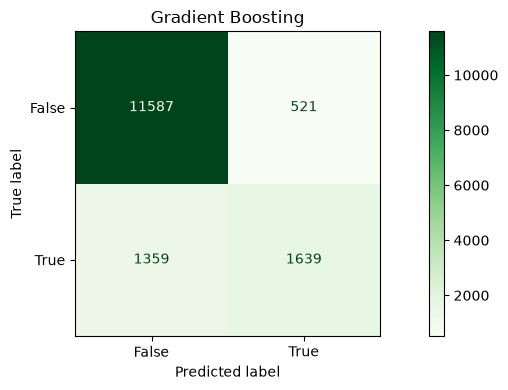

In [ ]:
fig, axes = plt.subplots(figsize=(10, 4))
ConfusionMatrixDisplay.from_estimator(pipe_gb, X_test_capped, y_test, ax=axes, cmap='Greens')
axes.set_title('Gradient Boosting')
plt.tight_layout()
plt.show()

# 9. Hyperparameter Tuning

## 9.1. Tuning for Best Model

In [53]:
param_gb = {
    'classifier__n_estimators': randint(100, 300),
    'classifier__learning_rate': uniform(0.01, 0.29),       # range: 0.01 - 0.30
    'classifier__max_depth': randint(2, 8),
    'classifier__min_samples_split': randint(2, 20),
    'classifier__min_samples_leaf': randint(1, 10),
    'classifier__subsample': uniform(0.6, 0.4),             # range: 0.6 - 1.0
    'classifier__max_features': ['sqrt', 'log2', None]
}

In [54]:
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

random_gb = RandomizedSearchCV(
    estimator=pipe_gb,
    param_distributions=param_gb,
    n_iter=15,
    scoring='roc_auc',
    cv=cv_strategy,
    verbose=2,
    random_state=42,
    n_jobs=-1
)

random_gb.fit(X_train_capped, y_train)

print('Best Parameters : ', random_gb.best_params_)
print('Best AUC-ROC Score (CV) : ', random_gb.best_score_)

Fitting 3 folds for each of 15 candidates, totalling 45 fits
Best Parameters :  {'classifier__learning_rate': np.float64(0.11861663446573512), 'classifier__max_depth': 6, 'classifier__max_features': None, 'classifier__min_samples_leaf': 8, 'classifier__min_samples_split': 8, 'classifier__n_estimators': 221, 'classifier__subsample': np.float64(0.662397808134481)}
Best AUC-ROC Score (CV) :  0.8480750043030634


## 9.2. Evaluation after Tuning

### 9.2.1. ROC-AUC

Before Tuning

In [56]:
y_pred_aucroc_gb = pipe_gb.predict_proba(X_test_capped)[:, 1]
fpr_gb, tpr_gb, _ = roc_curve(y_test, y_pred_aucroc_gb)
auc_gb = roc_auc_score(y_test, y_pred_aucroc_gb)

print('AUC Score : ', auc_gb)

if auc_gb > 0.9:
    print('AUC Status : Good' )
elif 0.9 > auc_gb > 0.8:
    print('AUC Status : Fair' )
elif 0.8 > auc_gb > 0.7:
    print('AUC Status : Decent' )
elif 0.7 > auc_gb > 0.6:
    print('AUC Status : Not Great' )
else :
    print('AUC Status : Poor' )

AUC Score :  0.8447166517574871
AUC Status : Fair


After Tuning

In [57]:
y_pred_aucroc_best = best_gb.predict_proba(X_test_capped)[:, 1]
fpr_best, tpr_best, _ = roc_curve(y_test, y_pred_aucroc_best)
auc_best = roc_auc_score(y_test, y_pred_aucroc_best)

print('AUC Score : ', auc_best)

if auc_best > 0.9:
    print('AUC Status : Good')
elif 0.9 > auc_best > 0.8:
    print('AUC Status : Fair')
elif 0.8 > auc_best > 0.7:
    print('AUC Status : Decent')
elif 0.7 > auc_best > 0.6:
    print('AUC Status : Not Great')
else:
    print('AUC Status : Poor')

AUC Score :  0.8547542045980219
AUC Status : Fair


### 9.2.2. Cross Validation

Before Tuning

In [58]:
roc_auc_train_cross_val = cross_validate(pipe_gb,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.85658864 0.85694186 0.85644523]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.8566585783713908
ROC-AUC Score - Std  - Cross Validation For Train set:  0.0002086915096330163
-------
ROC-AUC Score - All  - Cross Validation  :  [0.84689223 0.84097726 0.84421607]
ROC-AUC Score - Mean - Cross Validation  :  0.8440285191852054
ROC-AUC Score - Std  - Cross Validation  :  0.0024184128138068734


After Tuning

In [59]:
roc_auc_train_cross_val_best = cross_validate(best_gb,
                                         X_train_capped,
                                         y_train,
                                         cv=3,
                                         return_train_score=True,
                                         scoring='roc_auc'
                                        )

print('ROC-AUC Score - All  - Cross Validation For Train set : ', roc_auc_train_cross_val_best['train_score'])
print('ROC-AUC Score - Mean - Cross Validation For Train set: ', roc_auc_train_cross_val_best['train_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation For Train set: ', roc_auc_train_cross_val_best['train_score'].std())
print('-------')
print('ROC-AUC Score - All  - Cross Validation  : ', roc_auc_train_cross_val_best['test_score'])
print('ROC-AUC Score - Mean - Cross Validation  : ', roc_auc_train_cross_val_best['test_score'].mean())
print('ROC-AUC Score - Std  - Cross Validation  : ', roc_auc_train_cross_val_best['test_score'].std())

ROC-AUC Score - All  - Cross Validation For Train set :  [0.91839158 0.91917237 0.91855885]
ROC-AUC Score - Mean - Cross Validation For Train set:  0.9187075989702197
ROC-AUC Score - Std  - Cross Validation For Train set:  0.00033566113170297005
-------
ROC-AUC Score - All  - Cross Validation  :  [0.85100372 0.84479779 0.84972727]
ROC-AUC Score - Mean - Cross Validation  :  0.8485095946512072
ROC-AUC Score - Std  - Cross Validation  :  0.0026758744048435315


Setelah dilakukan evaluasi menggunakan ROC-AUC dan Cross Validation dari sebelum dan sesudah dilakukan Hyperparameter Tuning maka dapat disimpulkan bahwa model tersebut mengalami peningkatan performa yang lebih baik

# 10. Save Model

In [60]:
import pickle

pickle.dump(best_gb, open('model_gb.pkl', 'wb'))